### Example 1.4.8: Birthday Problem

Suppose a room contains $k$ people. Assume that each person's birthday is independently and uniformly distributed across the $365$ days of the year, excluding February 29.

We want to calculate the probability that **at least two people share the same birthday**.

#### Step 1: Count all possible birthday assignments

Each person has $365$ possible birthdays. By the multiplication rule, the total number of assignments is

$$
|\Omega| = 365^k.
$$

All assignments are equally likely under our assumptions.

#### Step 2: Count the complement

Directly counting assignments with at least one birthday match is difficult. Instead, consider the complementary event: **no two people share a birthday**.

For the first person, there are $365$ possible birthdays. The second person must have a different birthday, leaving $364$ choices. The third has $363$ choices, and so on.

For $k \leq 365$, the number of assignments with no matches is

$$
365 \times 364 \times 363 \times \cdots \times (365-k+1).
$$

Therefore,

$$
P(\text{no match})
=
\frac{365 \times 364 \times \cdots \times (365-k+1)}
{365^k}.
$$

#### Step 3: Apply the complement rule

The event of at least one match is the complement of the event of no matches. Hence,

$$
P(\text{at least one match})
=
1-P(\text{no match}).
$$

Thus, for $k \leq 365$,

$$
P(\text{at least one match})
=
1-\frac{365 \times 364 \times \cdots \times (365-k+1)}
{365^k}.
$$

For $k > 365$, a match is guaranteed by the pigeonhole principle, so the probability is $1$.

In [1]:
DAYS_IN_YEAR = 365

def birthday_match_probability(k):
    """Return the probability that at least two people share a birthday."""
    if k < 0:
        raise ValueError("The number of people cannot be negative.")

    if k > DAYS_IN_YEAR:
        return 1.0

    # Probability that all k birthdays are different
    p_no_match = 1.0

    for i in range(k):
        p_no_match *= (DAYS_IN_YEAR - i) / DAYS_IN_YEAR

    # Complement rule
    return 1 - p_no_match


# Test the formula for selected group sizes
for k in [2, 10, 23, 36, 50, 100, 365, 366]:
    probability = birthday_match_probability(k)

    print(
        f"k = {k:3}: "
        f"P(at least one match) = {probability:.10f} "
        f"({probability * 100:.6f}%)"
    )

k =   2: P(at least one match) = 0.0027397260 (0.273973%)
k =  10: P(at least one match) = 0.1169481777 (11.694818%)
k =  23: P(at least one match) = 0.5072972343 (50.729723%)
k =  36: P(at least one match) = 0.8321821064 (83.218211%)
k =  50: P(at least one match) = 0.9703735796 (97.037358%)
k = 100: P(at least one match) = 0.9999996928 (99.999969%)
k = 365: P(at least one match) = 1.0000000000 (100.000000%)
k = 366: P(at least one match) = 1.0000000000 (100.000000%)


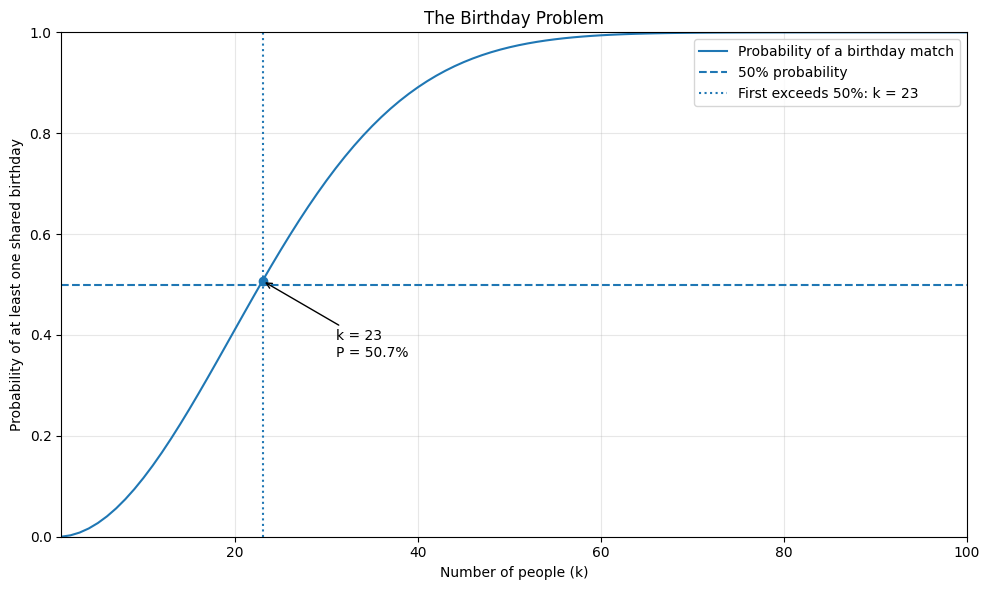

At k = 23, the probability is 50.7297%.


In [2]:
import matplotlib.pyplot as plt

DAYS_IN_YEAR = 365

def birthday_match_probability(k):
    """Probability that at least two people share a birthday."""
    if k < 0:
        raise ValueError("The number of people cannot be negative.")
    if k > DAYS_IN_YEAR:
        return 1.0

    p_no_match = 1.0
    for i in range(k):
        p_no_match *= (DAYS_IN_YEAR - i) / DAYS_IN_YEAR

    return 1 - p_no_match


# Calculate probabilities for group sizes from 1 to 100
group_sizes = range(1, 101)
probabilities = [
    birthday_match_probability(k) for k in group_sizes
]

# Find the first group size for which the probability exceeds 50%
threshold_k = next(
    k for k in range(1, 367)
    if birthday_match_probability(k) > 0.5
)
threshold_probability = birthday_match_probability(threshold_k)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(group_sizes, probabilities, label="Probability of a birthday match")
plt.axhline(
    y=0.5, linestyle="--",
    label="50% probability"
)
plt.axvline(
    x=threshold_k, linestyle=":",
    label=f"First exceeds 50%: k = {threshold_k}"
)
plt.scatter([threshold_k], [threshold_probability], zorder=3)
plt.annotate(
    f"k = {threshold_k}\nP = {threshold_probability:.1%}",
    xy=(threshold_k, threshold_probability),
    xytext=(threshold_k + 8, threshold_probability - 0.15),
    arrowprops={"arrowstyle": "->"}
)

plt.title("The Birthday Problem")
plt.xlabel("Number of people (k)")
plt.ylabel("Probability of at least one shared birthday")
plt.xlim(1, 100)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"At k = {threshold_k}, the probability is "
      f"{threshold_probability:.4%}.")

In [3]:
# Find the first group size with probability > 50%

DAYS = 365
p_no_match = 1.0

for k in range(1, DAYS + 2):
    if k <= DAYS:
        p_no_match *= (DAYS - k + 1) / DAYS

    p_match = 1 - p_no_match

    if p_match > 0.5:
        print(f"First group size exceeding 50%: k = {k}")
        print(f"P(no shared birthday) = {p_no_match:.6f}")
        print(f"P(at least one shared birthday) = 1 - {p_no_match:.6f}")
        print(f"Probability = {p_match:.2%}")
        break

First group size exceeding 50%: k = 23
P(no shared birthday) = 0.492703
P(at least one shared birthday) = 1 - 0.492703
Probability = 50.73%
